In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

import shap # for SHAP values


In [2]:
# sensors to be used in the model
sensors = ['Z-Axis Peak Velocity(mm/sec)', 'X-Axis Kurtosis', 'Frequency_L2_Current_Temperature', 'Frequency_L2_Z_Axis_Peak_Acceleration']

In [3]:
def prepare_data(combined, train_data_path, test_data_path = '', test_size=0.2, frequencies=None):
    if frequencies and combined:
        df = pd.read_csv(train_data_path)
        df, validation = remove_frequencies(df, frequencies)
        y = df['machine_state'].values
        df = df[sensors].values
        X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=test_size, random_state=42)
        val = validation[sensors].values
        val_y = validation['machine_state'].values
        return X_train, y_train, X_test, y_test, val, val_y
    elif frequencies:
        df_train = pd.read_csv(train_data_path)
        df_test = pd.read_csv(test_data_path)
        df_train, validation = remove_frequencies(df_train, frequencies)
        df_test, _ = remove_frequencies(df_test, frequencies)
        X_train = df_train[sensors].values
        y_train = df_train['machine_state'].values
        X_test = df_test[sensors].values
        y_test = df_test['machine_state'].values
        val = validation[sensors].values
        val_y = validation['machine_state'].values
        return X_train, y_train, X_test, y_test, val, val_y
    elif combined:
        df = pd.read_csv(train_data_path)
        y = df['machine_state'].values
        df = df[sensors].values
        X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=test_size, random_state=42)
        return X_train, y_train, X_test, y_test
    else:
        df_train = pd.read_csv(train_data_path)
        df_test = pd.read_csv(test_data_path)
        X_train = df_train[sensors].values
        y_train = df_train['machine_state'].values
        X_test = df_test[sensors].values
        y_test = df_test['machine_state'].values
        return X_train, y_train, X_test, y_test
    
def remove_frequencies(d, frequencies):
    removed = d[~d['Frequency L2 Current'].isin(frequencies)]
    rest = d[d['Frequency L2 Current'].isin(frequencies)]
    return rest, removed

def train_gradient_boosting(X_train, y_train, X_test, y_test, show_results=True):
    # standardize the data
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # train the model
    model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3)
    model.fit(X_train, y_train)
    
    if show_results:
        eval_model(model, X_test, y_test)
    
    return model

def eval_model(model, X_val, y_val):
    # predict the validation data
    scaler = StandardScaler()
    X_val = scaler.fit_transform(X_val)
    y_pred = model.predict(X_val)

    # calculate the accuracy
    accuracy = accuracy_score(y_val, y_pred)
    cm = confusion_matrix(y_val, y_pred)
    report = classification_report(y_val, y_pred)

    # print classification report
    print(report)
    print(f'Accuracy: {accuracy}')

    # plot confusion matrix
    plt.figure(figsize=(5, 2))
    sns.heatmap(cm, annot=True, fmt='d')
    plt.xlabel('Predicted')
    plt.ylabel('Truth')
    plt.show()

              precision    recall  f1-score   support

           0       0.91      0.68      0.78     13422
           1       0.44      0.78      0.56      4284

    accuracy                           0.71     17706
   macro avg       0.67      0.73      0.67     17706
weighted avg       0.79      0.71      0.73     17706

Accuracy: 0.7062012876990851


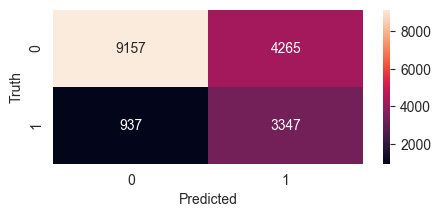

In [4]:
# model with balanced data
X_train, y_train, X_test, y_test = prepare_data(combined=False, train_data_path='../datasets/train_data.csv', test_data_path='../datasets/test_data.csv')
model = train_gradient_boosting(X_train, y_train, X_test, y_test)


              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3544
           1       0.97      0.97      0.97      1762

    accuracy                           0.98      5306
   macro avg       0.98      0.98      0.98      5306
weighted avg       0.98      0.98      0.98      5306

Accuracy: 0.9822842065586129


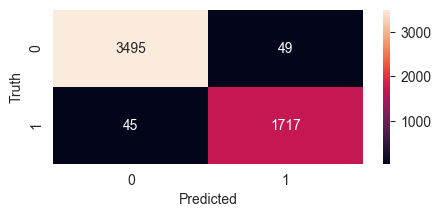

In [5]:
# model with all data
X_train, y_train, X_test, y_test = prepare_data(combined=True, train_data_path='../datasets/complete.csv', test_size=0.2)
model = train_gradient_boosting(X_train, y_train, X_test, y_test)


              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1294
           1       0.99      0.99      0.99       693

    accuracy                           1.00      1987
   macro avg       1.00      0.99      1.00      1987
weighted avg       1.00      1.00      1.00      1987

Accuracy: 0.9954705586311021


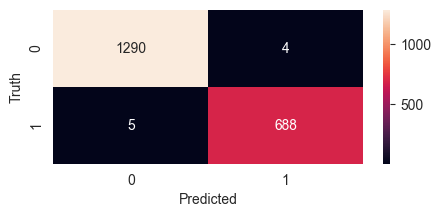

              precision    recall  f1-score   support

           0       0.74      0.99      0.84     11226
           1       0.90      0.27      0.41      5371

    accuracy                           0.75     16597
   macro avg       0.82      0.63      0.63     16597
weighted avg       0.79      0.75      0.70     16597

Accuracy: 0.7538109296860879


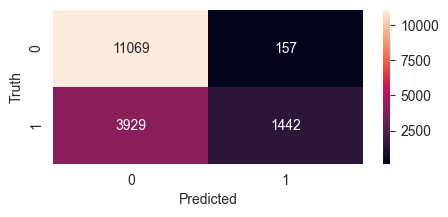

In [6]:
# model with all data and removing frequency 25
X_train, y_train, X_test, y_test, val, val_y = prepare_data(combined=True, train_data_path='../datasets/complete.csv', test_size=0.2, frequencies=[25])
model = train_gradient_boosting(X_train, y_train, X_test, y_test)
eval_model(model, val, val_y)

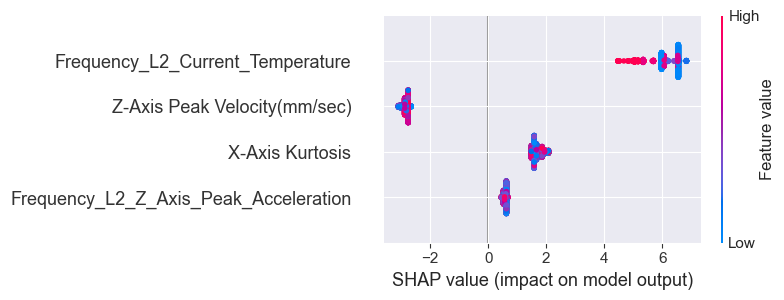

In [8]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test, feature_names=sensors)

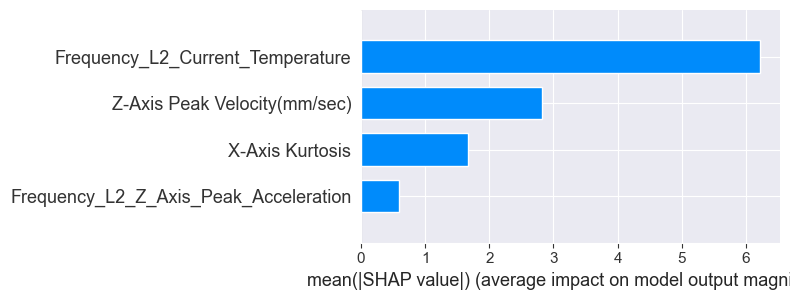

In [9]:
shap.summary_plot(shap_values, X_test, feature_names=sensors, plot_type='bar')

In [10]:
shap.dependence_plot('Z-Axis Peak Velocity(mm/sec)', shap_values[1], X_test, feature_names=sensors)

IndexError: index 4 is out of bounds for axis 0 with size 4